# Forest Cover Type: Exploratory Data Analysis

Visualizations of target balance, wilderness and soil indicators, terrain distributions, hydrology distances and feature correlations.

## Setup and data loading

Download `train.csv` from the Kaggle Forest Cover Type Prediction competition and place it in `data/`. Figures are saved to `figures/`.

In [2]:
from __future__ import annotations

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility for any sampling used in plots
rng = np.random.default_rng(42)

# Paths (edit if needed)

TRAIN_PATH = Path("data/train.csv")
TEST_PATH = Path("data/test.csv")

FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 160)


train = pd.read_csv(TRAIN_PATH)
train.head()

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area1,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Soil_Type1,Soil_Type2,Soil_Type3,Soil_Type4,Soil_Type5,Soil_Type6,Soil_Type7,Soil_Type8,Soil_Type9,Soil_Type10,Soil_Type11,Soil_Type12,Soil_Type13,Soil_Type14,Soil_Type15,Soil_Type16,Soil_Type17,Soil_Type18,Soil_Type19,Soil_Type20,Soil_Type21,Soil_Type22,Soil_Type23,Soil_Type24,Soil_Type25,Soil_Type26,Soil_Type27,Soil_Type28,Soil_Type29,Soil_Type30,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,242642,2881,130,22,210,54,1020,250,221,88,342,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1
1,309891,3005,351,14,242,-16,1371,194,215,159,842,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,287847,3226,63,14,618,2,1092,232,210,107,2018,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1
3,516307,3298,317,8,661,60,752,198,233,174,1248,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
4,124860,3080,35,6,175,26,3705,219,227,144,2673,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


## 2. Sanity checks

We verify:
1. Missing values and duplicates
2. One hot consistency for wilderness and soil blocks
3. Column grouping for continuous, wilderness, and soil features


In [3]:
print("Shape:", train.shape)
print("Columns:", len(train.columns))

missing_cells = int(train.isna().sum().sum())
dup_rows = int(train.duplicated().sum())

print("Missing cells:", missing_cells)
print("Duplicate rows:", dup_rows)

target_col = "Cover_Type" if "Cover_Type" in train.columns else None
id_col = "Id" if "Id" in train.columns else None

wilderness_cols = [c for c in train.columns if c.startswith("Wilderness_Area")]
soil_cols = [c for c in train.columns if c.startswith("Soil_Type")]

excluded = set(([target_col] if target_col else []) + ([id_col] if id_col else []) + wilderness_cols + soil_cols)
continuous_cols = [c for c in train.columns if c not in excluded]

print("Continuous columns:", continuous_cols)
print("Wilderness columns:", wilderness_cols)
print("Soil columns:", len(soil_cols))

if wilderness_cols:
    wilderness_sum = train[wilderness_cols].sum(axis=1)
    print("Wilderness row sum unique values:", sorted(wilderness_sum.unique())[:10])

if soil_cols:
    soil_sum = train[soil_cols].sum(axis=1)
    print("Soil row sum unique values:", sorted(soil_sum.unique())[:10])

Shape: (15120, 56)
Columns: 56
Missing cells: 0
Duplicate rows: 0
Continuous columns: ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points']
Wilderness columns: ['Wilderness_Area1', 'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4']
Soil columns: 40
Wilderness row sum unique values: [np.int64(1)]
Soil row sum unique values: [np.int64(1)]


## Helper for saving figures

In [4]:
def savefig(name: str) -> Path:
    path = FIG_DIR / name
    plt.tight_layout()
    plt.savefig(path, dpi=200, bbox_inches="tight")
    print("Saved:", path.as_posix())
    return path

## Figure 1. Cover type distribution

Saved: figures/fig01_cover_type_distribution.png


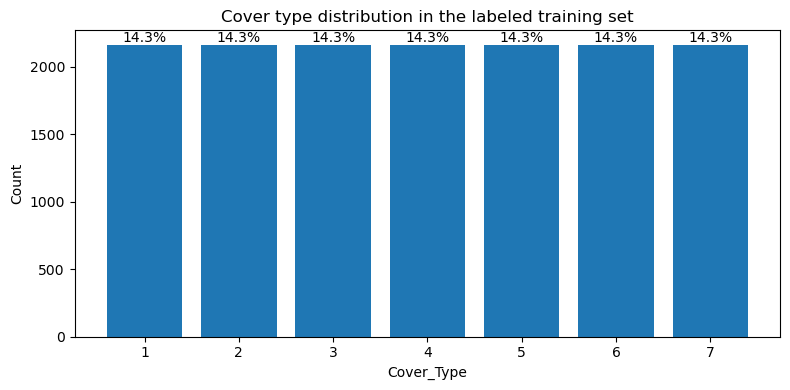

In [5]:
if target_col is None:
    raise ValueError("Cover_Type column not found in this training file.")

counts = train[target_col].value_counts().sort_index()
freq = counts / counts.sum()

plt.figure(figsize=(8, 4))
plt.bar(counts.index.astype(str), counts.values)
plt.xlabel("Cover_Type")
plt.ylabel("Count")
plt.title("Cover type distribution in the labeled training set")

for i, (cls, c) in enumerate(counts.items()):
    pct = 100.0 * float(freq.loc[cls])
    plt.text(i, c, f"{pct:.1f}%", ha="center", va="bottom")

savefig("fig01_cover_type_distribution.png")
plt.show()

## Figure 2. Wilderness marginal prevalence

Saved: figures/fig02_wilderness_prevalence.png


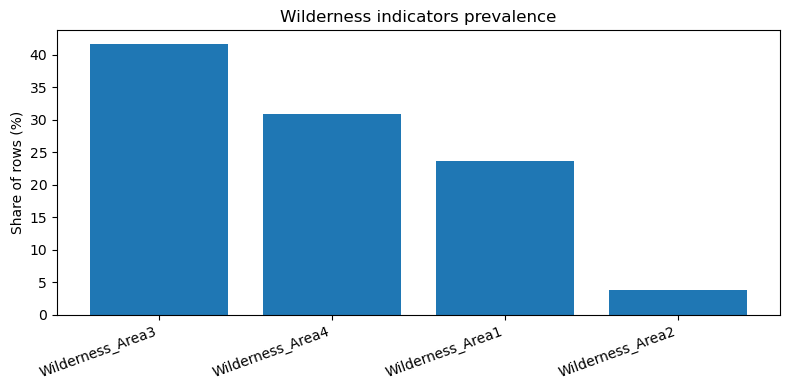

In [6]:
if not wilderness_cols:
    raise ValueError("No Wilderness_Area columns found.")

w_counts = train[wilderness_cols].sum().sort_values(ascending=False)
w_share = (w_counts / len(train)) * 100.0

plt.figure(figsize=(8, 4))
plt.bar(w_counts.index, w_share.values)
plt.xticks(rotation=20, ha="right")
plt.ylabel("Share of rows (%)")
plt.title("Wilderness indicators prevalence")

savefig("fig02_wilderness_prevalence.png")
plt.show()

## Figure 3. Wilderness by cover type (stacked proportions)

Saved: figures/fig03_wilderness_by_cover_type.png


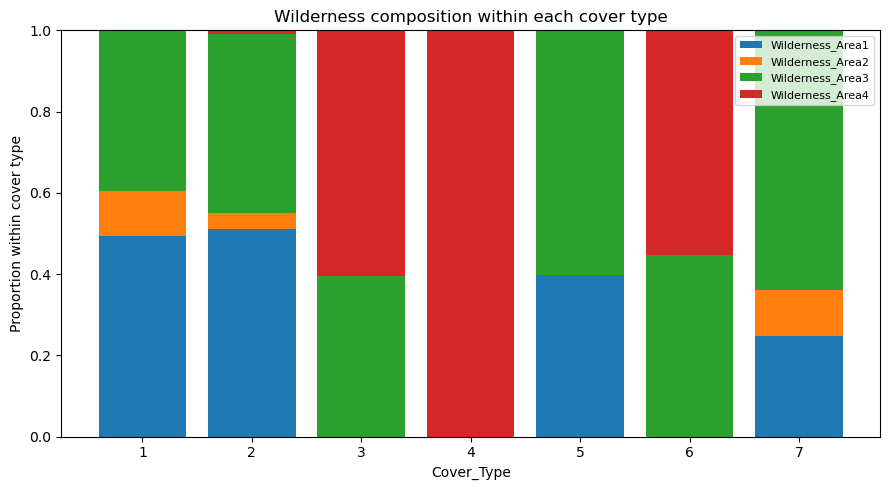

In [7]:
w_idx = train[wilderness_cols].idxmax(axis=1)
ct = pd.crosstab(train[target_col], w_idx, normalize="index")
ct = ct[[c for c in wilderness_cols if c in ct.columns]]

plt.figure(figsize=(9, 5))
bottom = np.zeros(len(ct))
x = np.arange(len(ct.index))

for col in ct.columns:
    vals = ct[col].values
    plt.bar(x, vals, bottom=bottom, label=col)
    bottom += vals

plt.xticks(x, ct.index.astype(str))
plt.xlabel("Cover_Type")
plt.ylabel("Proportion within cover type")
plt.title("Wilderness composition within each cover type")
plt.legend(loc="upper right", fontsize=8)

savefig("fig03_wilderness_by_cover_type.png")
plt.show()

## Figure 4. Soil prevalence long tail and top soil types

Saved: figures/fig04a_soil_long_tail.png


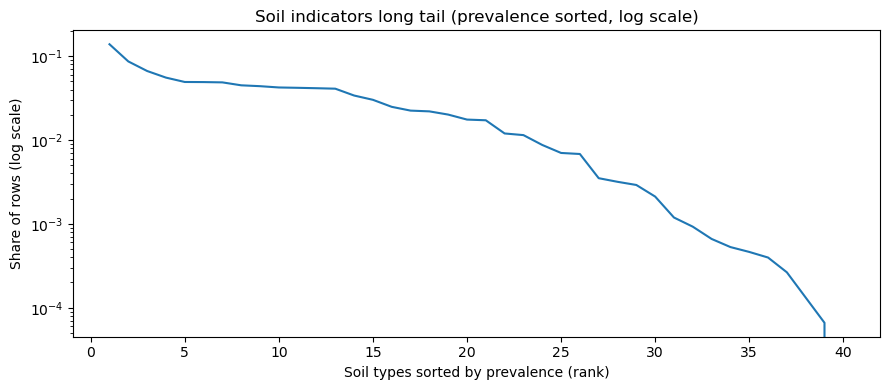

Saved: figures/fig04b_top_soil_types.png


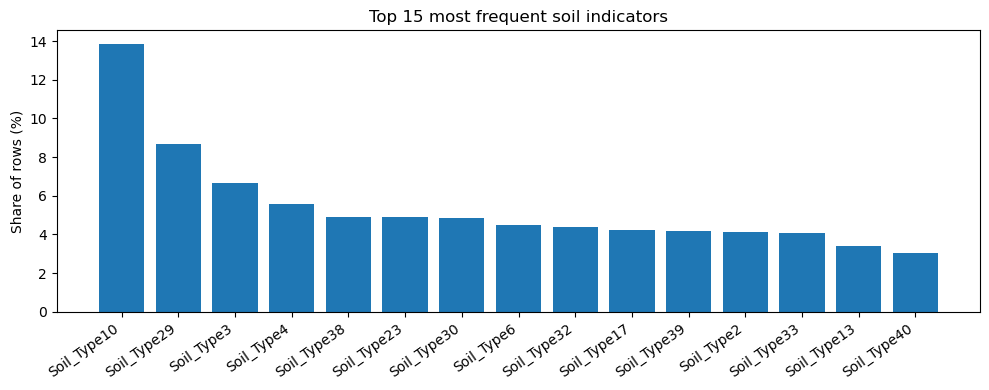

In [8]:
if not soil_cols:
    raise ValueError("No Soil_Type columns found.")

soil_counts = train[soil_cols].sum().sort_values(ascending=False)
soil_share = soil_counts / len(train)

plt.figure(figsize=(9, 4))
plt.plot(np.arange(1, len(soil_share) + 1), soil_share.values)
plt.yscale("log")
plt.xlabel("Soil types sorted by prevalence (rank)")
plt.ylabel("Share of rows (log scale)")
plt.title("Soil indicators long tail (prevalence sorted, log scale)")
savefig("fig04a_soil_long_tail.png")
plt.show()

top_k = 15
top = soil_share.head(top_k) * 100.0

plt.figure(figsize=(10, 4))
plt.bar(top.index, top.values)
plt.xticks(rotation=35, ha="right")
plt.ylabel("Share of rows (%)")
plt.title(f"Top {top_k} most frequent soil indicators")
savefig("fig04b_top_soil_types.png")
plt.show()

## Figure 5. Zero inflation in hydrology distances

Saved: figures/fig05a_hydrology_zero_inflation.png


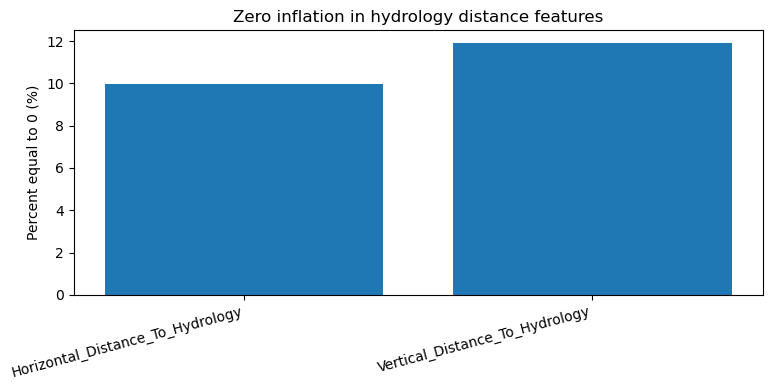

Saved: figures/fig05b_Horizontal_Distance_To_Hydrology_nonzero_hist.png


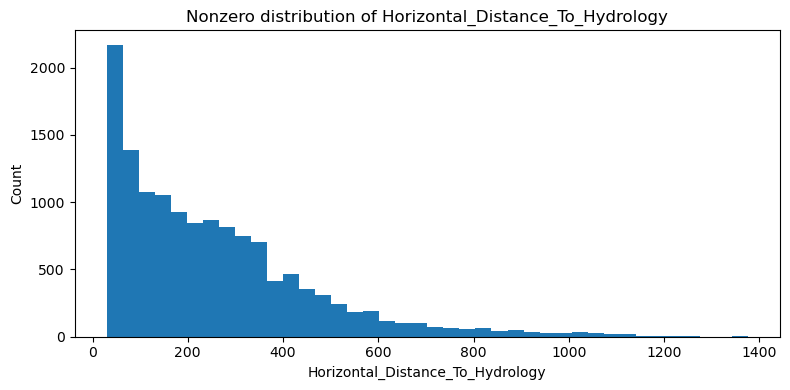

Saved: figures/fig05b_Vertical_Distance_To_Hydrology_nonzero_hist.png


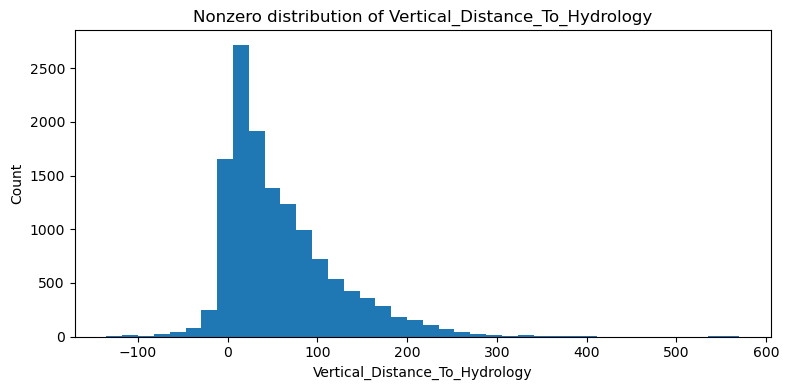

In [9]:
h_hydro = "Horizontal_Distance_To_Hydrology"
v_hydro = "Vertical_Distance_To_Hydrology"

if h_hydro in train.columns and v_hydro in train.columns:
    zero_frac = pd.Series({
        h_hydro: (train[h_hydro] == 0).mean(),
        v_hydro: (train[v_hydro] == 0).mean(),
    }) * 100.0

    plt.figure(figsize=(8, 4))
    plt.bar(zero_frac.index, zero_frac.values)
    plt.xticks(rotation=15, ha="right")
    plt.ylabel("Percent equal to 0 (%)")
    plt.title("Zero inflation in hydrology distance features")
    savefig("fig05a_hydrology_zero_inflation.png")
    plt.show()

    for col in [h_hydro, v_hydro]:
        nonzero = train.loc[train[col] != 0, col]
        plt.figure(figsize=(8, 4))
        plt.hist(nonzero.values, bins=40)
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.title(f"Nonzero distribution of {col}")
        savefig(f"fig05b_{col}_nonzero_hist.png")
        plt.show()
else:
    print("Hydrology distance columns not found, skipping.")

## Figure 6. Key continuous feature distributions (histograms)

Saved: figures/fig06_Elevation_hist.png


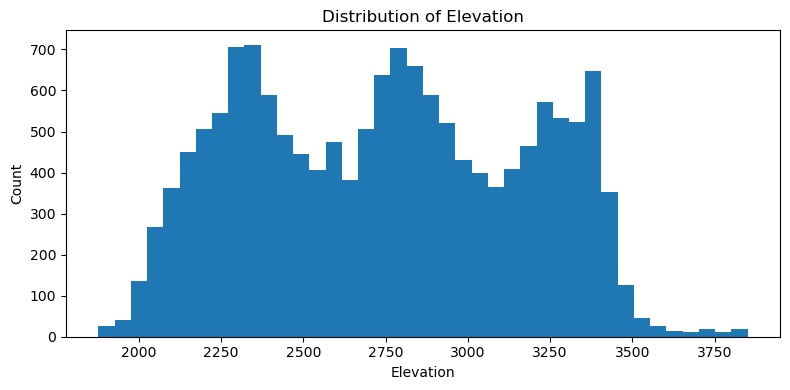

Saved: figures/fig06_Slope_hist.png


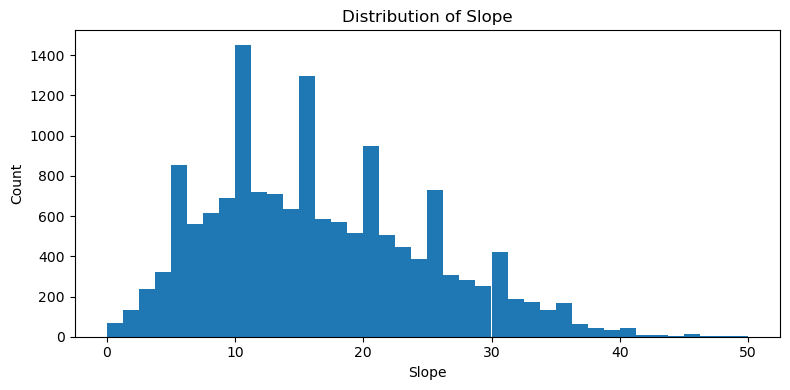

Saved: figures/fig06_Horizontal_Distance_To_Roadways_hist.png


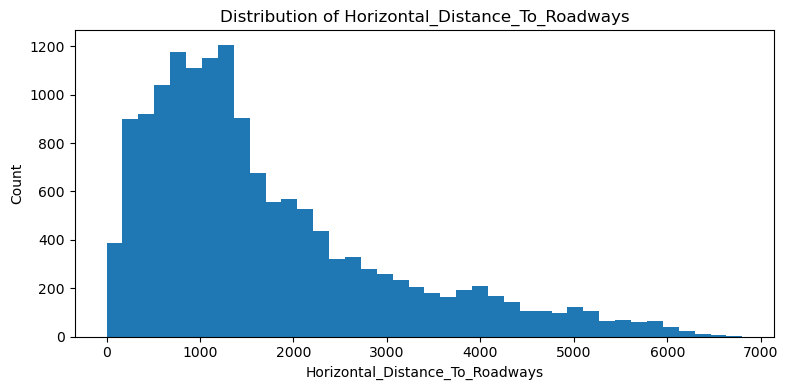

Saved: figures/fig06_Horizontal_Distance_To_Fire_Points_hist.png


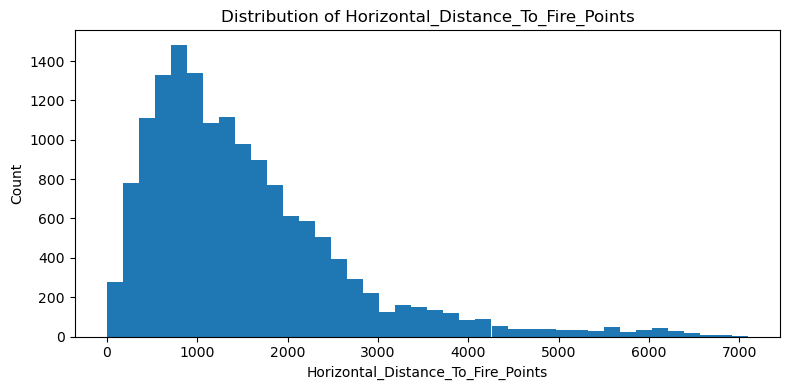

Saved: figures/fig06_Hillshade_9am_hist.png


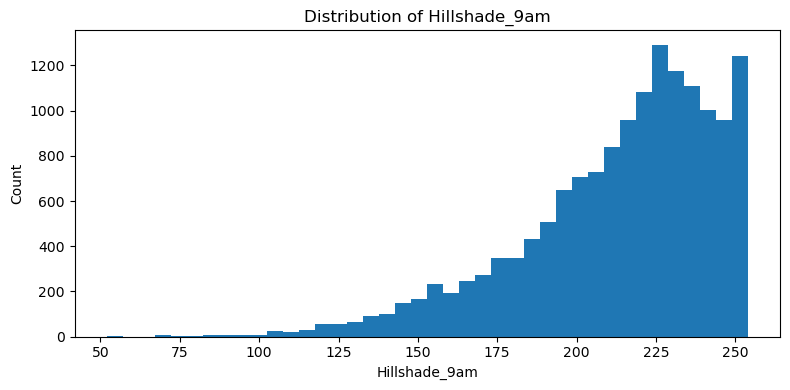

Saved: figures/fig06_Hillshade_Noon_hist.png


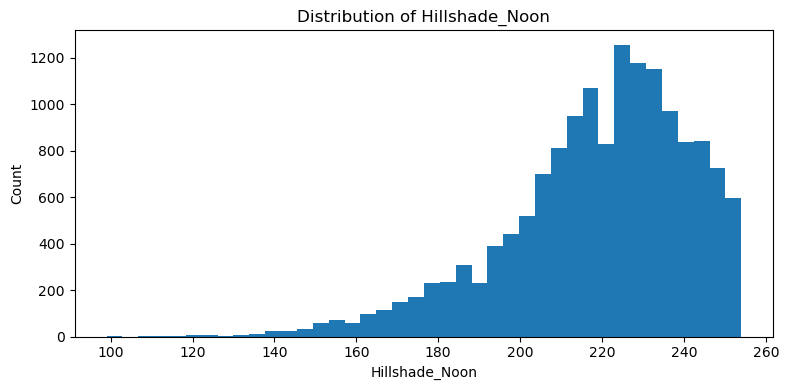

Saved: figures/fig06_Hillshade_3pm_hist.png


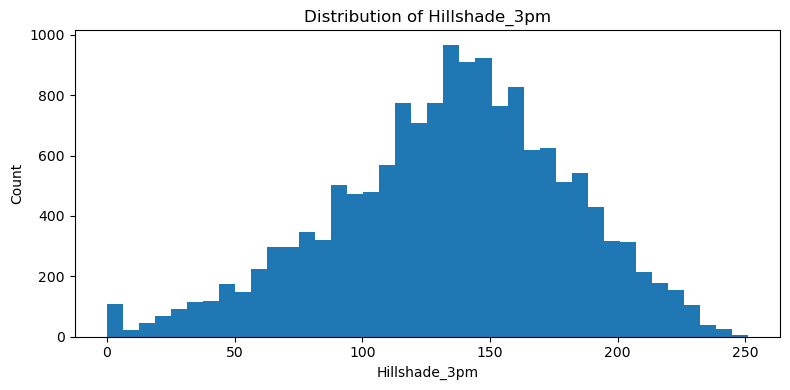

In [10]:
key_continuous = [
    c for c in [
        "Elevation",
        "Slope",
        "Horizontal_Distance_To_Roadways",
        "Horizontal_Distance_To_Fire_Points",
        "Hillshade_9am",
        "Hillshade_Noon",
        "Hillshade_3pm",
    ]
    if c in train.columns
]

for col in key_continuous:
    plt.figure(figsize=(8, 4))
    plt.hist(train[col].values, bins=40)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.title(f"Distribution of {col}")
    savefig(f"fig06_{col}_hist.png")
    plt.show()

## Figure 7. Boxplots of key continuous features by cover type

Saved: figures/fig07_Elevation_boxplot_by_cover.png


<Figure size 900x400 with 0 Axes>

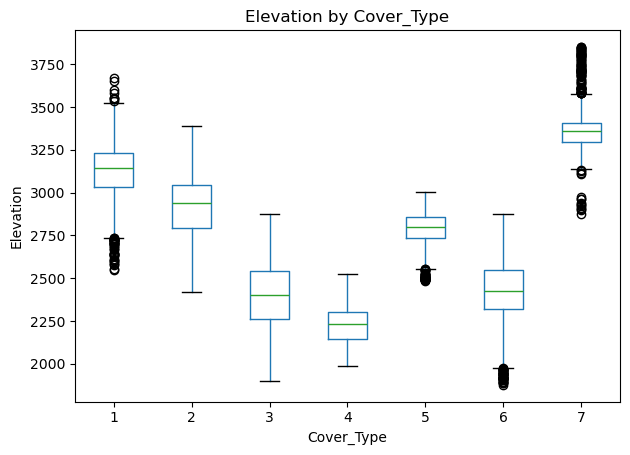

Saved: figures/fig07_Slope_boxplot_by_cover.png


<Figure size 900x400 with 0 Axes>

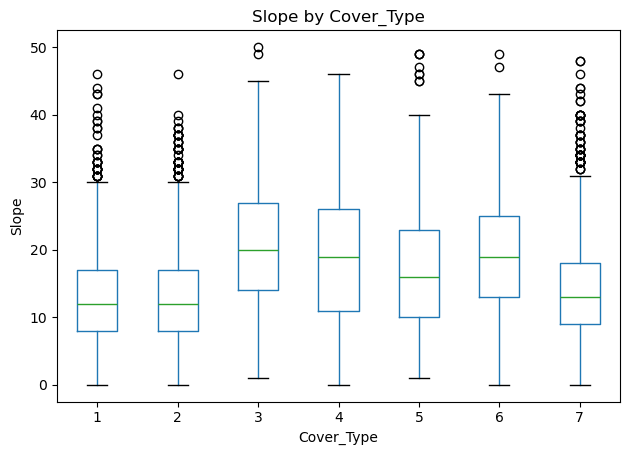

Saved: figures/fig07_Horizontal_Distance_To_Hydrology_boxplot_by_cover.png


<Figure size 900x400 with 0 Axes>

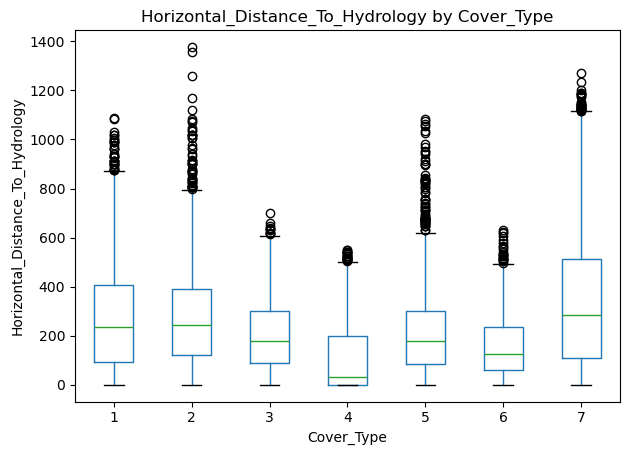

Saved: figures/fig07_Vertical_Distance_To_Hydrology_boxplot_by_cover.png


<Figure size 900x400 with 0 Axes>

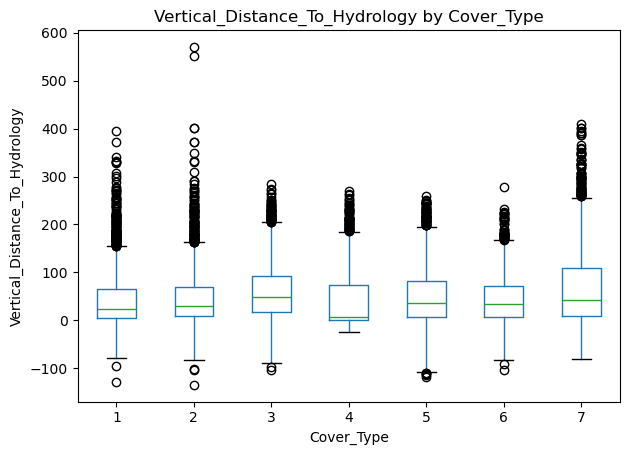

Saved: figures/fig07_Horizontal_Distance_To_Roadways_boxplot_by_cover.png


<Figure size 900x400 with 0 Axes>

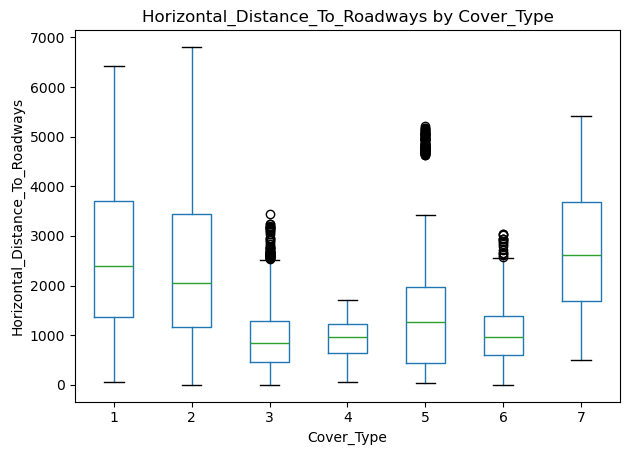

Saved: figures/fig07_Horizontal_Distance_To_Fire_Points_boxplot_by_cover.png


<Figure size 900x400 with 0 Axes>

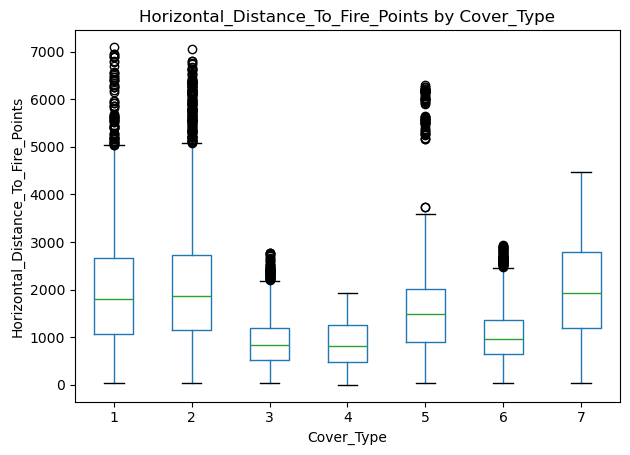

In [11]:
box_cols = [
    c for c in [
        "Elevation",
        "Slope",
        "Horizontal_Distance_To_Hydrology",
        "Vertical_Distance_To_Hydrology",
        "Horizontal_Distance_To_Roadways",
        "Horizontal_Distance_To_Fire_Points",
    ]
    if c in train.columns
]

for col in box_cols:
    plt.figure(figsize=(9, 4))
    train.boxplot(column=col, by=target_col, grid=False)
    plt.suptitle("")
    plt.title(f"{col} by Cover_Type")
    plt.xlabel("Cover_Type")
    plt.ylabel(col)
    savefig(f"fig07_{col}_boxplot_by_cover.png")
    plt.show()

## Figure 8. Correlation heatmap for continuous features

Saved: figures/fig08_continuous_correlation_heatmap.png


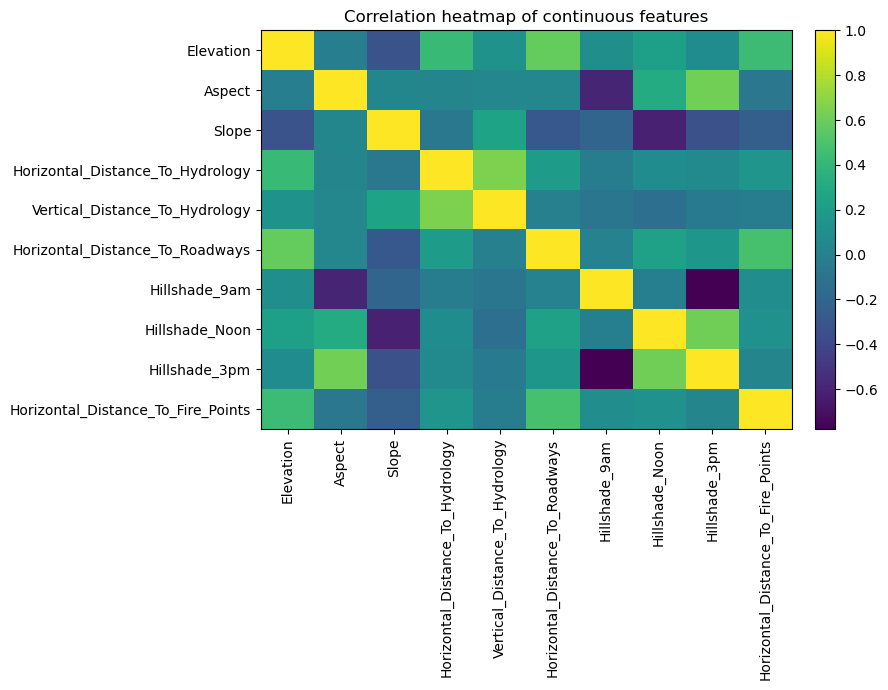

In [12]:
if not continuous_cols:
    print("No continuous columns detected, skipping heatmap.")
else:
    corr = train[continuous_cols].corr(numeric_only=True)

    plt.figure(figsize=(9, 7))
    im = plt.imshow(corr.values, aspect="auto")
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.index)), corr.index)
    plt.title("Correlation heatmap of continuous features")
    savefig("fig08_continuous_correlation_heatmap.png")
    plt.show()

## Figure 9. Aspect polar histogram (rose plot)

Saved: figures/fig09_aspect_polar_hist.png


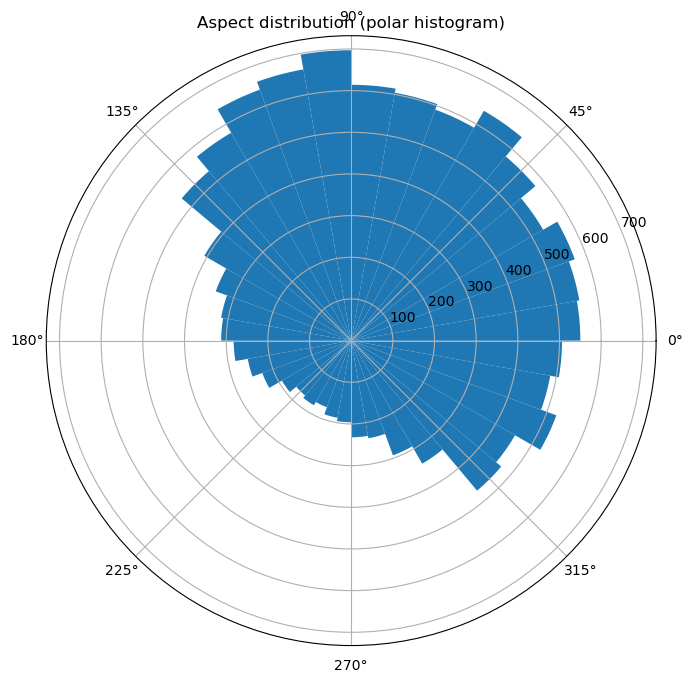

In [13]:
aspect_col = "Aspect"
if aspect_col in train.columns:
    theta = np.deg2rad(train[aspect_col].values)

    bins = 36
    counts, edges = np.histogram(theta, bins=bins, range=(0, 2 * np.pi))
    widths = np.diff(edges)

    plt.figure(figsize=(7, 7))
    ax = plt.subplot(111, polar=True)
    ax.bar(edges[:-1], counts, width=widths, align="edge")
    ax.set_title("Aspect distribution (polar histogram)")
    savefig("fig09_aspect_polar_hist.png")
    plt.show()
else:
    print("Aspect column not found, skipping.")

## Figures

The generated plots are saved under `figures/` and illustrate the dataset patterns discussed in the report.